In [2]:
%matplotlib inline

from collections import OrderedDict
from importlib import reload
import os, sys

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm

import numpy as np
import pandas as pd
import scipy.stats

from astropy.table import Table
from astropy.stats import mad_std
from astropy.constants import iau2012 as const

from scipy.stats import spearmanr, gaussian_kde
import statsmodels.api as sm

sys.path.append('../')
from aklpyutils.utils_stats import *


from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MaxNLocator
from shapely.geometry import Point
from shapely.ops import cascaded_union

from jsplottools.sun_plot_tools.general import mpl_setup
from jsplottools.sun_plot_tools.ax import *
from jsplottools.sun_plot_tools.fig import *
mpl_setup(figtype='paper-1/3')
params = {'legend.fontsize': 'x-large',          
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
plt.rcParams.update(params)

In [3]:
from key_dirs import *
from aklpyutils.utils_spacing import *

['ic1954', 'ic5273', 'ngc0253', 'ngc0300', 'ngc0628', 'ngc0685', 'ngc1097', 'ngc1511', 'ngc1546', 'ngc1637', 'ngc1792', 'ngc2903', 'ngc2997', 'ngc3137', 'ngc3351', 'ngc3489', 'ngc3511', 'ngc3521', 'ngc3621', 'ngc3627', 'ngc4254', 'ngc4298', 'ngc4459', 'ngc4476', 'ngc4477', 'ngc4536', 'ngc4548', 'ngc4569', 'ngc4596', 'ngc4731', 'ngc4781', 'ngc4826', 'ngc4941', 'ngc5068', 'ngc5128', 'ngc5236', 'ngc5643', 'ngc7456', 'ngc7496', 'ngc7793']


**Spacing vs. Resolution**

In [4]:
spacing_list = []
res_list = []
noise_list = []
native_list = []

spacing_dict = {}

matched_list = [
    '../data/full_cloud_cats/matched_120pc/',
    '../data/full_cloud_cats/matched_150pc/',
    '../data/full_cloud_cats/matched_200pc/',
    '../data/full_cloud_cats/matched_60pc/',
    '../data/full_cloud_cats/matched_90pc/',
    ]
lownoise_list = [
    '../data/full_cloud_cats/homogen_120pc_63mK/',
    '../data/full_cloud_cats/homogen_150pc_46mK/',
    '../data/full_cloud_cats/homogen_200pc_37mK/',
    '../data/full_cloud_cats/homogen_60pc_83mK/',
    '../data/full_cloud_cats/homogen_90pc_78mK/',
    ]
highnoise_list = [
    '../data/full_cloud_cats/homogen_120pc_148mK/',
    '../data/full_cloud_cats/homogen_150pc_116mK/',
    '../data/full_cloud_cats/homogen_200pc_92mK/',
    '../data/full_cloud_cats/homogen_60pc_193mK/',
    '../data/full_cloud_cats/homogen_90pc_153mK/',
    ]

for this_cat_dir in cat_dir_list:

    in_dir = cat_root_dir + this_cat_dir+'/'
    print(in_dir)
    
    # Find all catalogs in the directory
    cat_glob = glob.glob(in_dir+'*_props.fits')

    sub_spacing_list = []
    sub_res_list = []
    sub_noise_list = []
    sub_native_list = []

    for in_cat_file in cat_glob:
        
        out_cat_file = in_cat_file.replace('_props.fits','_props_valueadded.fits')
        cat = Table.read(out_cat_file)
            
        spacing_vec = np.array(cat['DIST_NN1_PC'])        
        spacing_list.append(spacing_vec)
        sub_spacing_list.append(spacing_vec)
        
        res_vec = np.array(cat['BEAMMAJ_PC'])        
        res_list.append(res_vec)
        sub_res_list.append(res_vec)
        
        noise_vec = np.array(cat['TMAX_K'])/np.array(cat['S2N'])
        noise_list.append(noise_vec)
        sub_noise_list.append(noise_vec)
        
        native_vec = np.zeros_like(noise_vec) + (in_dir.count('native') >= 1)
        native_list.append(native_vec)
        sub_native_list.append(native_vec)
        
        if (in_dir.count('native') >= 1):
            this_spacing_dict = calc_stats(spacing_vec, doprint=False)
            this_spacing_dict['MED_RES_PC'] = np.median(res_vec)
            this_spacing_dict['IS_NATIVE'] = True        
            this_spacing_dict['IS_HIGHNOISE'] = False
            this_spacing_dict['IS_LOWNOISE'] = False
            this_spacing_dict['IS_MATCHED'] = False    
            spacing_dict[out_cat_file] = this_spacing_dict        
            
    sub_noise_vec = np.concatenate(sub_noise_list)
    sub_spacing_vec = np.concatenate(sub_spacing_list)
    sub_res_vec = np.concatenate(sub_res_list)
    sub_native_vec = np.concatenate(sub_native_list)
    
    this_spacing_dict = calc_stats(sub_spacing_vec, doprint=False)
    this_spacing_dict['MED_RES_PC'] = np.median(sub_res_vec)
    this_spacing_dict['IS_NATIVE'] = (in_dir.count('native') >= 1)        
    this_spacing_dict['IS_HIGHNOISE'] = (in_dir in highnoise_list)        
    this_spacing_dict['IS_LOWNOISE'] = (in_dir in lownoise_list)        
    this_spacing_dict['IS_MATCHED'] = (in_dir in matched_list)        
    spacing_dict[in_dir] = this_spacing_dict        
            
noise_vec = np.concatenate(noise_list)
spacing_vec = np.concatenate(spacing_list)
res_vec = np.concatenate(res_list)
native_vec = np.concatenate(native_list)    

../cloud_cats_fits/homogen_120pc_148mK/


ValueError: need at least one array to concatenate

In [4]:
fid_cat_tabs = {}
fid_cat_stats = {}
for this_source in source_list:
    this_fid_cat = fid_cat_dict[this_source].replace('_props.fits','_props_valueadded.fits')
    print(this_fid_cat)
    fid_cat_tabs[this_source] = Table.read(this_fid_cat)    
    stat_dict = {}
    fid_cat_stats[this_source] = stat_dict

../data/full_cloud_cats/homogen_150pc_46mK/ic1954_12m+7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ic5273_12m+7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ngc0253_7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ngc0300_7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ngc0628_12m+7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ngc0685_12m+7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ngc1097_12m+7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ngc1511_12m+7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ngc1546_12m+7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_cats/homogen_150pc_46mK/ngc1637_12m+7m+tp_co21_150pc_46mK_props_valueadded.fits
../data/full_cloud_c

In [5]:
noise_vec = np.concatenate(noise_list)
spacing_vec = np.concatenate(spacing_list)
res_vec = np.concatenate(res_list)
native_vec = np.concatenate(native_list)
print(len(noise_vec), len(spacing_vec), len(res_vec), len(native_vec))

197970 197970 197970 197970


In [6]:
source_list_ra = np.array(source_list)

mass_ra = np.zeros(len(source_list_ra))
lco_ra = np.zeros(len(source_list_ra))
sfr_ra = np.zeros(len(source_list_ra))
lstar_ra = np.zeros(len(source_list_ra))
incl_ra = np.zeros(len(source_list_ra))

for ii, this_source in enumerate(source_list_ra):
    deets = deets_dict[this_source]
    mass_ra[ii] = float(deets['props_mstar'])
    sfr_ra[ii] = float(deets['props_sfr'])
    lco_ra[ii] = float(deets['lco_phangs'])
    incl_ra[ii] = float(deets['orient_incl'])
    deg_to_pc = float(np.pi/180.*deets['dist']*1e3)
    lstar_ra[ii] = float(deets['size_scalelength']/3600.*deg_to_pc)        
        
mass_order = np.argsort(mass_ra)
lco_order = np.argsort(lco_ra)
sfr_order = np.argsort(sfr_ra)
lstar_order = np.argsort(lstar_ra)

/tmp/ipykernel_2199960/2344690063.py:13: UserWarning: Warning: converting a masked element to nan.
  lco_ra[ii] = float(deets['lco_phangs'])


**Plot resolution vs spacing**....

In [11]:
x_list = []
y_list = []

for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_NATIVE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    x_list.append(this_x)
    y_list.append(this_y)

x_vec = np.array(x_list)
y_vec = np.array(y_list)
ind = np.isfinite(x_vec)*np.isfinite(y_vec)
x_vec = x_vec[ind]
y_vec = y_vec[ind]

print("Native resolution numbers for nearest_neighbor spacing:")
print("Median diff [log]: ", np.nanmedian(y_vec-x_vec))
print("Median diff [linear]: ", 10.**np.nanmedian(y_vec-x_vec))
print("Rank correlation: ", scipy.stats.spearmanr(x_vec,y_vec))


Native resolution numbers for nearest_neighbor spacing:
Median diff [log]:  0.4738785616255181
Median diff [linear]:  2.977683686571978
Rank correlation:  SpearmanrResult(correlation=0.5786823771765671, pvalue=4.340439633842609e-09)


/home/leroy.42/anaconda3/lib/python3.8/site-packages/matplotlib/axes/_base.py:2141: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


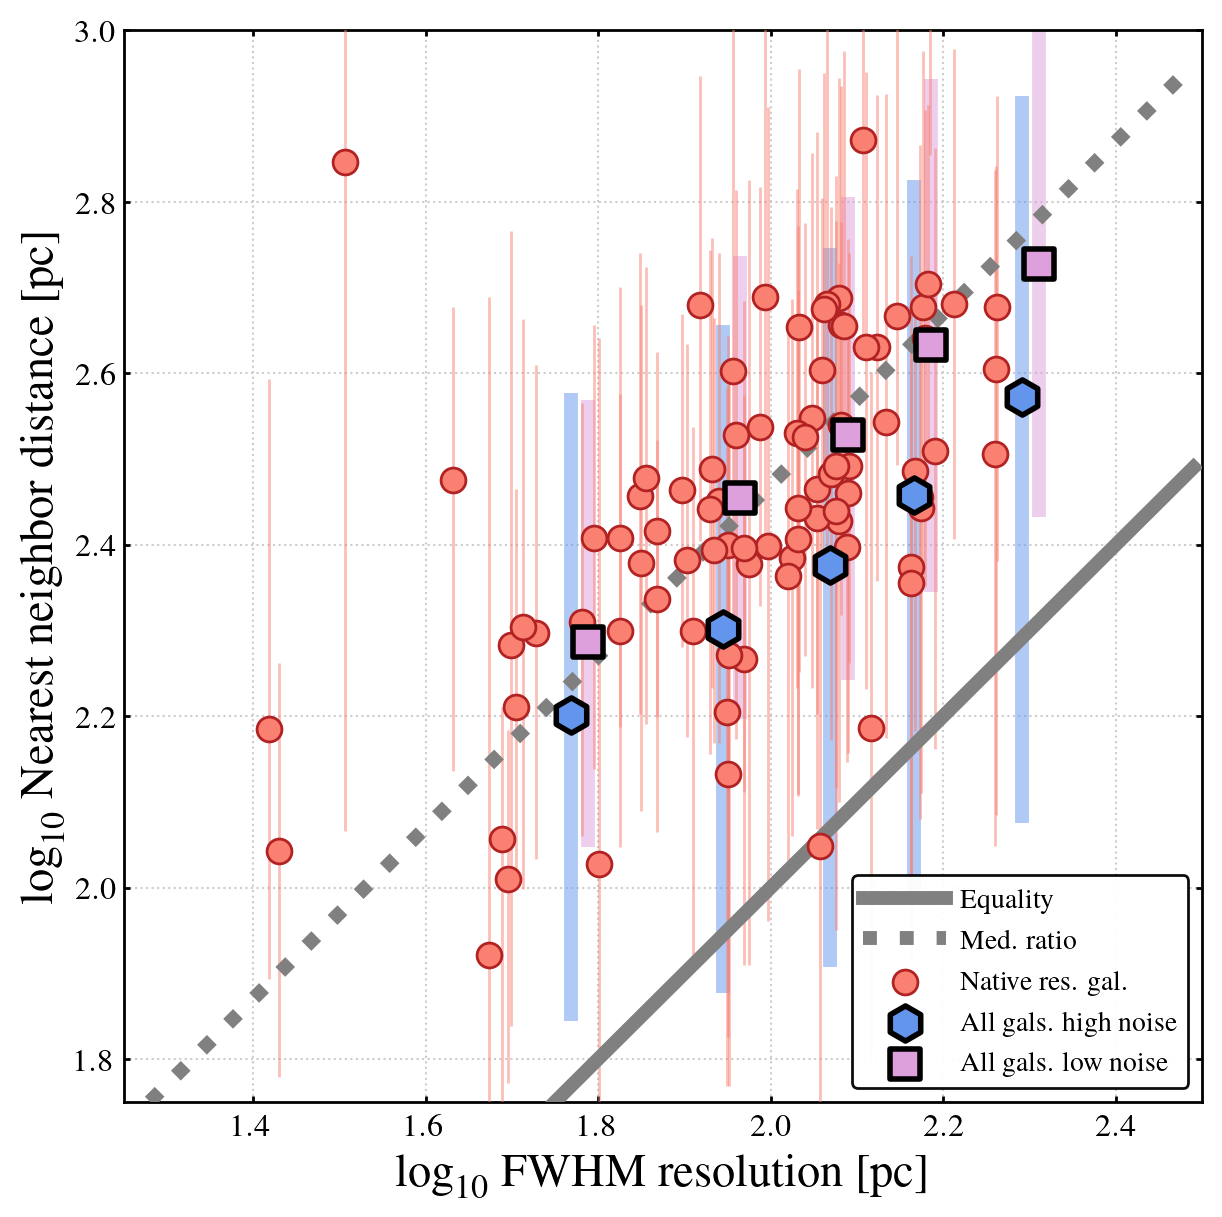

In [8]:
png_name = '../plots/spacing_vs_res.png'

xmin = 1.25
xmax = 2.5
ymin = 1.75
ymax = 3.0
#xticks = [-1.0,-0.5,0.,0.5,1.,1.5,2.]
#yticks = [-0.5,-0.375,-0.25,-0.125,0.0]

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ FWHM resolution [pc]'
ylabel = r'$\log_{10}$ Nearest neighbor distance [pc]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

#ind = (native_vec == 1)
#noise = np.random.normal(size=np.sum(ind))*0.005
#x = np.log10(res_vec[ind])+noise
#y = np.log10(spacing_vec[ind])
#z = np.log10(calc_local_density(x,y,support=(0.025,0.025)))
#axes.scatter(x, y,
#             marker='o', s=10, c=z, cmap='gray', edgecolor='gray',linewidth=0.25,
#             label=r'Individ. peaks (color shows density)', zorder=2)

first_native = True
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_NATIVE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_native:
        first_native = False
        label = r'Native res. gal.'
    else:
        label = None
    axes.scatter(this_x, this_y,
                marker='o', s=80, facecolor='salmon', edgecolor='firebrick', zorder=4,
                label=label)
    axes.errorbar(this_x, this_y, [[this_y-this_lo],[this_hi-this_y]],
                marker='.', color='salmon', ecolor='salmon', zorder=3, capsize=0, alpha=0.5)

first_fullcat = True
shift = -0.01
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_HIGHNOISE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_fullcat:
        first_fullcat = False
        label = r'All gals. high noise'
    else:
        label = None    
    axes.scatter(this_x+shift, this_y,
                marker='h', s=160, facecolor='cornflowerblue', edgecolor='black', zorder=6,
                label=label, linewidth=2)
    axes.errorbar(this_x+shift, this_y, [[this_y-this_lo],[this_hi-this_y]],
                  marker='.', color='cornflowerblue', ecolor='cornflowerblue', 
                  zorder=1, capsize=0, elinewidth=5,alpha=0.5)
    
first_fullcat = True
shift = +0.01
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_LOWNOISE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_fullcat:
        first_fullcat = False
        label = r'All gals. low noise'
    else:
        label = None
            
    axes.scatter(this_x+shift, this_y,
                marker='s', s=120, facecolor='plum', edgecolor='black', zorder=6,
                label=label, linewidth=2)
    axes.errorbar(this_x+shift, this_y, [[this_y-this_lo],[this_hi-this_y]],
                  marker='.', color='plum', ecolor='plum', 
                  zorder=0, capsize=0, elinewidth=5, alpha=0.5)
    
axes.legend(fancybox=True, framealpha=0.95, loc='lower right', 
            ncol=1, fontsize=10, handlelength=3)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

/tmp/ipykernel_3778782/2992138212.py:63: RuntimeWarning: divide by zero encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/2992138212.py:63: RuntimeWarning: invalid value encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/2992138212.py:64: RuntimeWarning: divide by zero encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/2992138212.py:64: RuntimeWarning: invalid value encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/2992138212.py:66: RuntimeWarning: divide by zero encountered in log10
  axes.scatter(np.log10(x_vec), np.log10(y_vec), marker='o', s=10
/tmp/ipykernel_3778782/2992138212.py:66: RuntimeWarning: invalid value encountered in log10
  axes.scatter(np.log10(x_vec), np.log10(y_vec), marker='o', s=10
/tmp/ipykernel_3778782/2992138212.py:70: RuntimeWarning: divide by ze

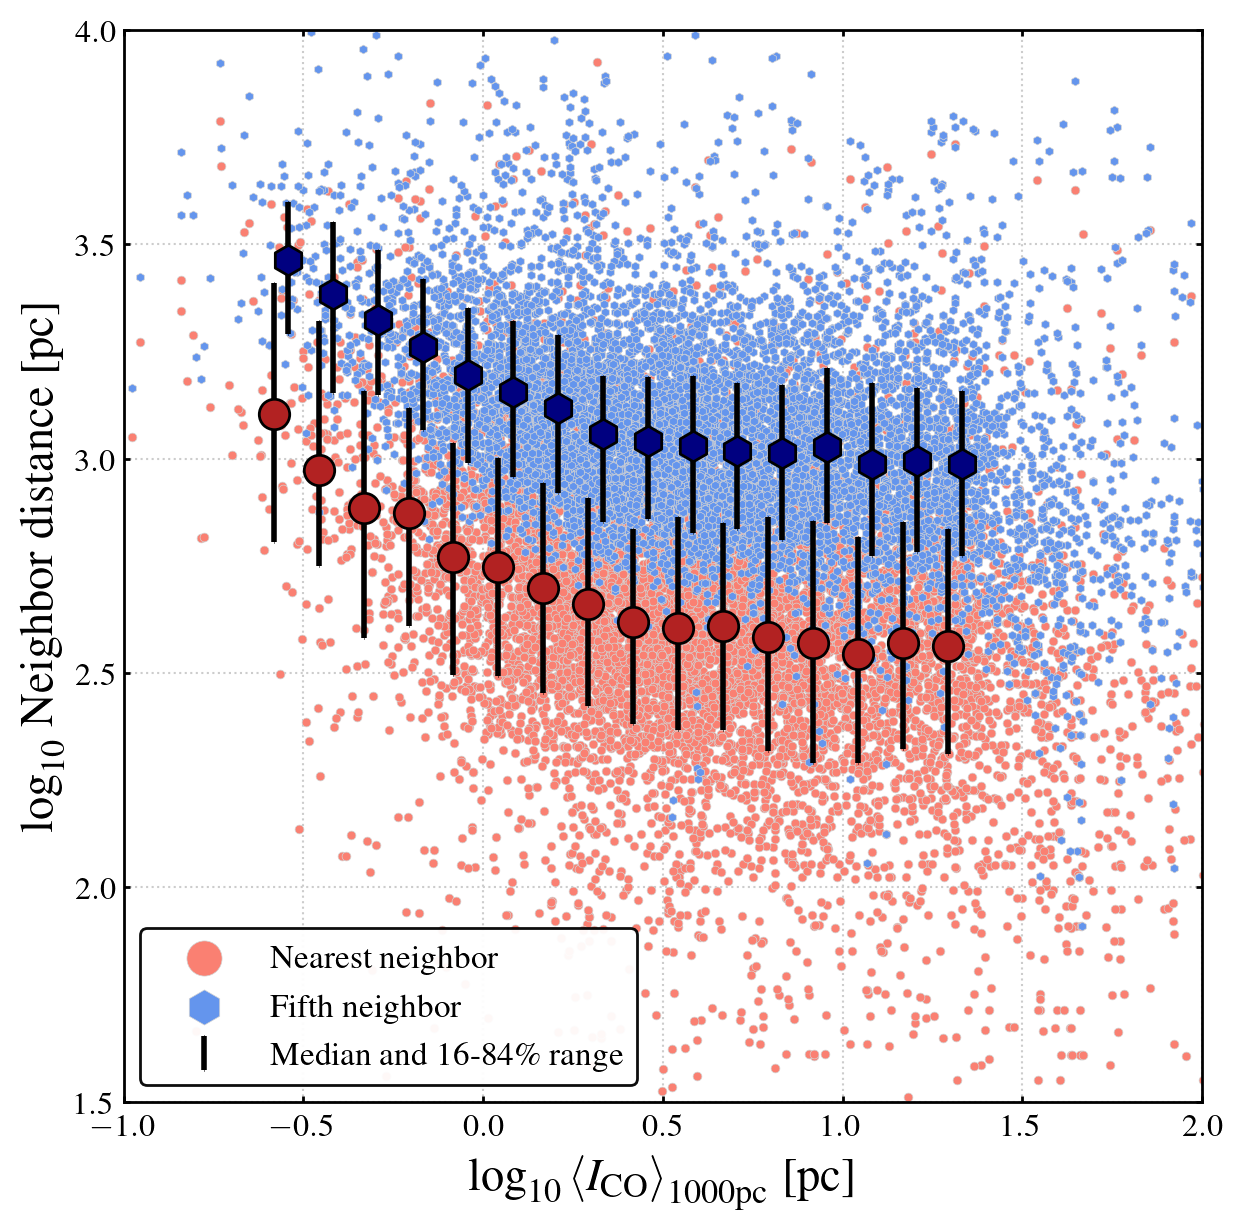

In [36]:
png_name = '../plots/dist_vs_ico.png'

xmin = -1.
xmax = 2.
ymin = 1.5
ymax = 4.0

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10} \left< I_{\rm CO} \right>_{\rm 1000 pc}$ [pc]'
ylabel = r'$\log_{10}$ Neighbor distance [pc]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
ex_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    this_x = np.array(this_tab['ICO21_1KPC'])
    this_ex = np.array(this_tab['EICO21_1KPC'])
    this_y = np.array(this_tab['DIST_NN1_PC'])
    this_z = np.array(this_tab['DIST_NN5_PC'])
    x_list.append(this_x)
    ex_list.append(this_ex)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.625,1.5,0.125)

ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)

axes.scatter(np.log10(x_vec), np.log10(y_vec), marker='o', s=10
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'Nearest neighbor')

axes.scatter(np.log10(x_vec), np.log10(z_vec), marker='h', s=10
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'Fifth neighbor')

shift = 0.02
axes.scatter(ybins['xmid']-shift, np.log10(ybins['50']), marker='o', s=120
             , facecolor='firebrick', edgecolor='black'
             , zorder=5)
axes.errorbar(ybins['xmid']-shift, np.log10(ybins['50']),
                [np.log10(ybins['84'])-np.log10(ybins['50']),
                 np.log10(ybins['50'])-np.log10(ybins['16'])],
              color='black', capsize=0.1, elinewidth=2, fmt='none',
              marker='o',s=10,
              zorder=3,label=r'Median and 16-84\% range')

axes.scatter(zbins['xmid']+shift, np.log10(zbins['50']), marker='h', s=120
             , facecolor='navy', edgecolor='black'
             , zorder=6)
axes.errorbar(zbins['xmid']+shift, np.log10(zbins['50']),
                [np.log10(zbins['84'])-np.log10(zbins['50']),
                 np.log10(zbins['50'])-np.log10(zbins['16'])],
              color='black', capsize=0.1, elinewidth=2, fmt='none',
              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.95, loc='lower left', 
            ncol=1, fontsize=12, handlelength=3, markerscale=4)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

/tmp/ipykernel_3778782/499114649.py:64: RuntimeWarning: divide by zero encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/499114649.py:64: RuntimeWarning: invalid value encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/499114649.py:65: RuntimeWarning: divide by zero encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/499114649.py:65: RuntimeWarning: invalid value encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/499114649.py:68: RuntimeWarning: divide by zero encountered in log10
  axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=10
/tmp/ipykernel_3778782/499114649.py:68: RuntimeWarning: invalid value encountered in log10
  axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=10
/tmp/ipykernel_3778782/499114649.py:73: RuntimeWarning: divide by zero enco

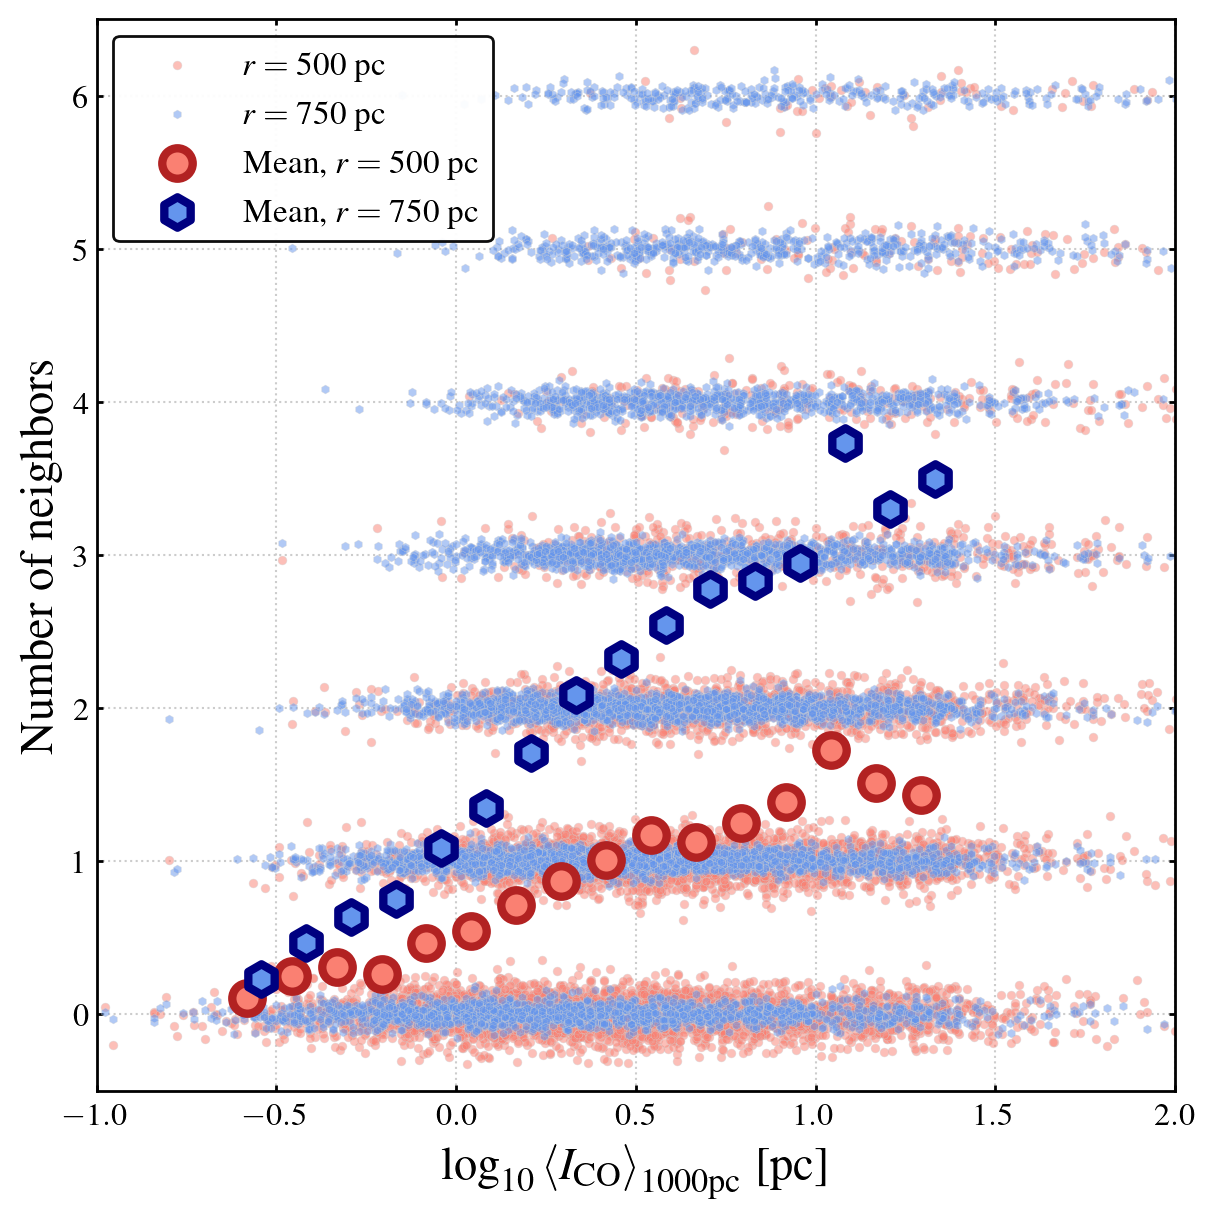

In [94]:
png_name = '../plots/nn_vs_ico.png'

xmin = -1.
xmax = 2.
ymin = -0.5
ymax = 6.5

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10} \left< I_{\rm CO} \right>_{\rm 1000 pc}$ [pc]'
ylabel = r'Number of neighbors'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
ex_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    #print(this_source)
    this_x = np.array(this_tab['ICO21_1KPC'])
    this_ex = np.array(this_tab['EICO21_1KPC'])
    this_y = np.array(this_tab['NEIGHBORS_500PC'])
    this_z = np.array(this_tab['NEIGHBORS_750PC'])
    x_list.append(this_x)
    ex_list.append(this_ex)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.625,1.5,0.125)

ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)

y_noise = y_vec*0. + np.random.normal(size=len(y_vec))*0.10
axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=10
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$r=500$~pc',alpha=0.5)

z_noise = z_vec*0. + np.random.normal(size=len(z_vec))*0.05
axes.scatter(np.log10(x_vec), (z_vec+z_noise), marker='h', s=10
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$r=750$~pc',alpha=0.5)

shift = 0.02
axes.scatter(ybins['xmid']-shift, (ybins['mean']), marker='o', s=120
             , facecolor='salmon', edgecolor='firebrick', linewidth=3
             , zorder=6, label=r'Mean, $r=500$~pc')
#axes.errorbar(ybins['xmid']-shift, (ybins['mean']), (ybins['stddev'])
#              , color='black', capsize=0.1, elinewidth=2, fmt='none'
#              , marker='o',s=10
#              , zorder=3,label=r'Median and std. dev.')

axes.scatter(zbins['xmid']+shift, (zbins['mean']), marker='h', s=120
             , facecolor='cornflowerblue', edgecolor='navy', linewidth=3
             , zorder=6, label=r'Mean, $r=750$~pc')
#axes.errorbar(zbins['xmid']+shift,(zbins['mean']),
#                [(zbins['84'])-(zbins['50']),
#                 (zbins['50'])-(zbins['16'])],
#              color='black', capsize=0.1, elinewidth=2, fmt='none',
#              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.95, loc='upper left', 
            ncol=1, fontsize=12, handlelength=3, markerscale=1)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

/tmp/ipykernel_3778782/3725379122.py:68: RuntimeWarning: divide by zero encountered in log10
  axes.scatter((x_vec), np.log10(y_vec), marker='o', s=10


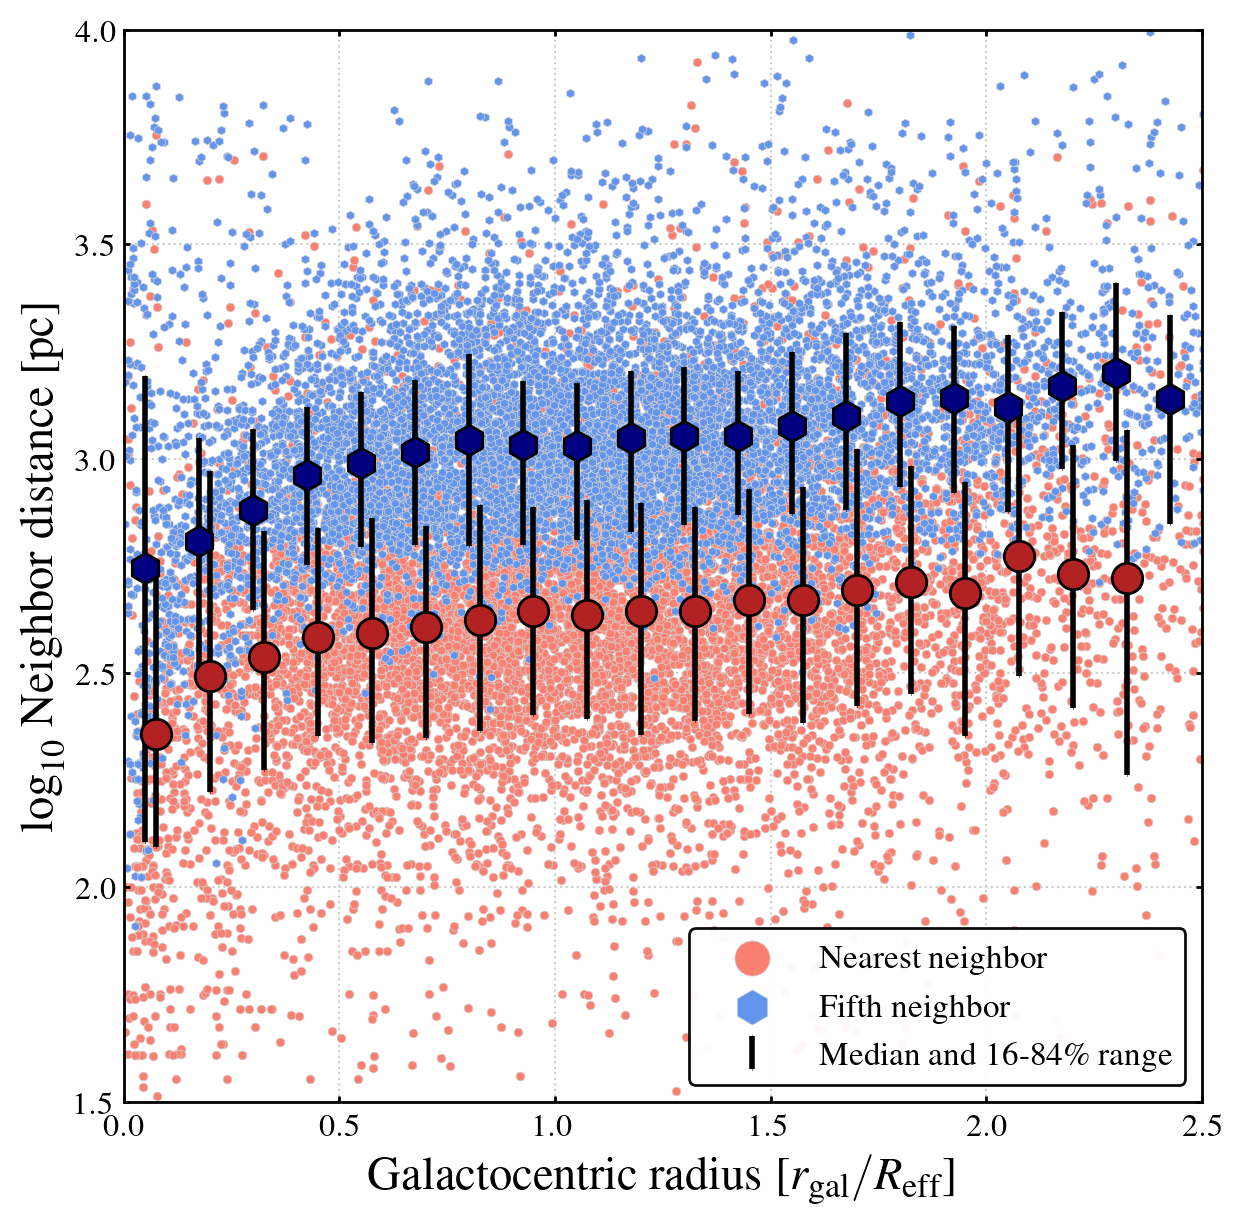

In [61]:
png_name = '../plots/dist_vs_rgal.png'

xmin = 0.0
xmax = 2.5
ymin = 1.5
ymax = 4.0

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'Galactocentric radius [$r_{\rm gal}/R_{\rm eff}$]'
ylabel = r'$\log_{10}$ Neighbor distance [pc]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
ex_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    deets = deets_dict[this_source]
    this_size = np.array(deets['size_reff'])        
    this_x = np.array(this_tab['RGAL_DEG'])*3600./this_size
    this_y = np.array(this_tab['DIST_NN1_PC'])
    this_z = np.array(this_tab['DIST_NN5_PC'])
    x_list.append(this_x)
    ex_list.append(this_ex)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.0625,2.5,0.125)

ybins = bin_data((x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data((x_vec), z_vec, xlo=xlo, xhi=xhi)

axes.scatter((x_vec), np.log10(y_vec), marker='o', s=10
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'Nearest neighbor')

shift = 0.05
axes.scatter(ybins['xmid']-shift, np.log10(ybins['50']), marker='o', s=120
             , facecolor='firebrick', edgecolor='black'
             , zorder=5)
axes.errorbar(ybins['xmid']-shift, np.log10(ybins['50']),
                [np.log10(ybins['84'])-np.log10(ybins['50']),
                 np.log10(ybins['50'])-np.log10(ybins['16'])],
              color='black', capsize=0.1, elinewidth=2, fmt='none',
              marker='o',s=10,
              zorder=3,label=r'Median and 16-84\% range')

axes.scatter(zbins['xmid']+shift, np.log10(zbins['50']), marker='h', s=120
             , facecolor='navy', edgecolor='black'
             , zorder=6)
axes.errorbar(zbins['xmid']+shift, np.log10(zbins['50']),
                [np.log10(zbins['84'])-np.log10(zbins['50']),
                 np.log10(zbins['50'])-np.log10(zbins['16'])],
              color='black', capsize=0.1, elinewidth=2, fmt='none',
              zorder=4)

axes.scatter((x_vec), np.log10(z_vec), marker='h', s=10
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'Fifth neighbor')

legend = axes.legend(fancybox=True, framealpha=0.95, loc='lower right', 
            ncol=1, fontsize=12, handlelength=3, markerscale=4)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

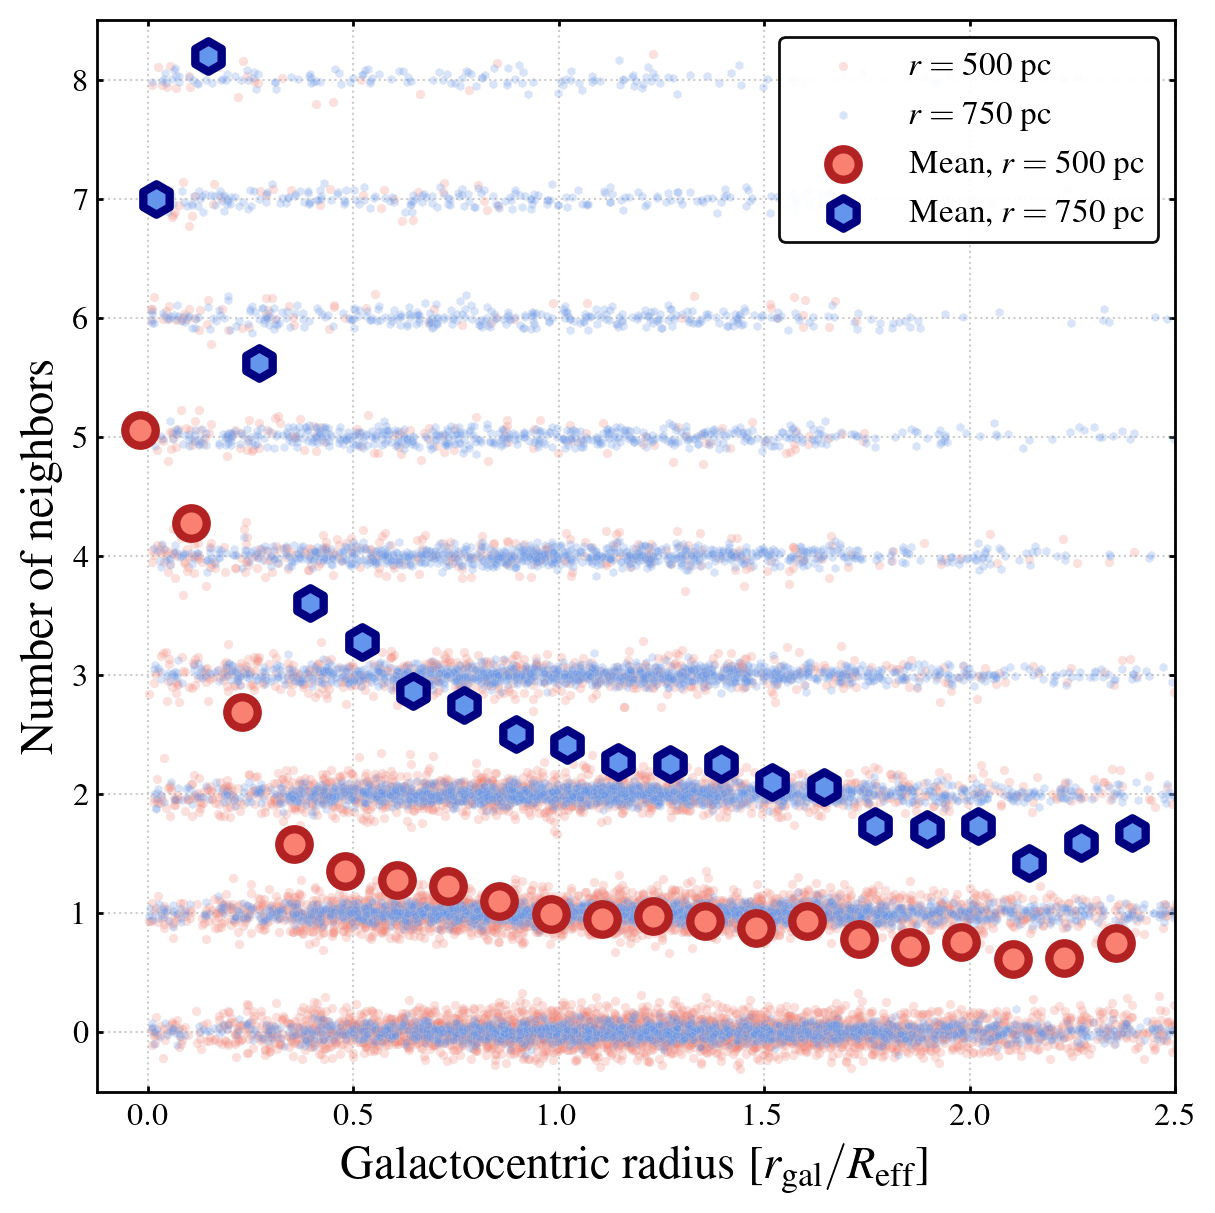

In [95]:
png_name = '../plots/nn_vs_rgal.png'

xmin = -0.125
xmax = 2.5
ymin = -0.5
ymax = 8.5

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'Galactocentric radius [$r_{\rm gal}/R_{\rm eff}$]'
ylabel = r'Number of neighbors'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    deets = deets_dict[this_source]
    this_size = np.array(deets['size_reff'])        
    this_x = np.array(this_tab['RGAL_DEG'])*3600./this_size
    this_y = np.array(this_tab['NEIGHBORS_500PC'])
    this_z = np.array(this_tab['NEIGHBORS_750PC'])
    x_list.append(this_x)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.0625,2.5,0.125)

ybins = bin_data((x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data((x_vec), z_vec, xlo=xlo, xhi=xhi)

y_noise = y_vec*0. + np.random.normal(size=len(y_vec))*0.10
axes.scatter((x_vec), (y_vec+y_noise), marker='o', s=10
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$r=500$~pc',alpha=0.25)

z_noise = z_vec*0. + np.random.normal(size=len(z_vec))*0.05
axes.scatter((x_vec), (z_vec+z_noise), marker='h', s=10
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$r=750$~pc',alpha=0.25)

shift = 0.02
axes.scatter(ybins['xmid']-shift, (ybins['mean']), marker='o', s=120
             , facecolor='salmon', edgecolor='firebrick', linewidth=3
             , zorder=5, label=r'Mean, $r=500$~pc')
#axes.errorbar(ybins['xmid']-shift, (ybins['mean']), (ybins['stddev'])
#              , color='black', capsize=0.1, elinewidth=2, fmt='none'
#              , marker='o',s=10
#              , zorder=3,label=r'Median and std. dev.')

axes.scatter(zbins['xmid']+shift, (zbins['mean']), marker='h', s=120
             , facecolor='cornflowerblue', edgecolor='navy', linewidth=3
             , zorder=6, label=r'Mean, $r=750$~pc')
#axes.errorbar(zbins['xmid']+shift,(zbins['mean']),
#                [(zbins['84'])-(zbins['50']),
#                 (zbins['50'])-(zbins['16'])],
#              color='black', capsize=0.1, elinewidth=2, fmt='none',
#              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.95, loc='upper right', 
            ncol=1, fontsize=12, handlelength=3, markerscale=1)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

/tmp/ipykernel_3778782/1016398810.py:66: RuntimeWarning: divide by zero encountered in log10
  axes.scatter((x_vec), np.log10(y_vec), marker='o', s=10
/tmp/ipykernel_3778782/1016398810.py:66: RuntimeWarning: invalid value encountered in log10
  axes.scatter((x_vec), np.log10(y_vec), marker='o', s=10
/tmp/ipykernel_3778782/1016398810.py:70: RuntimeWarning: divide by zero encountered in log10
  axes.scatter((x_vec), np.log10(z_vec), marker='h', s=10
/tmp/ipykernel_3778782/1016398810.py:70: RuntimeWarning: invalid value encountered in log10
  axes.scatter((x_vec), np.log10(z_vec), marker='h', s=10


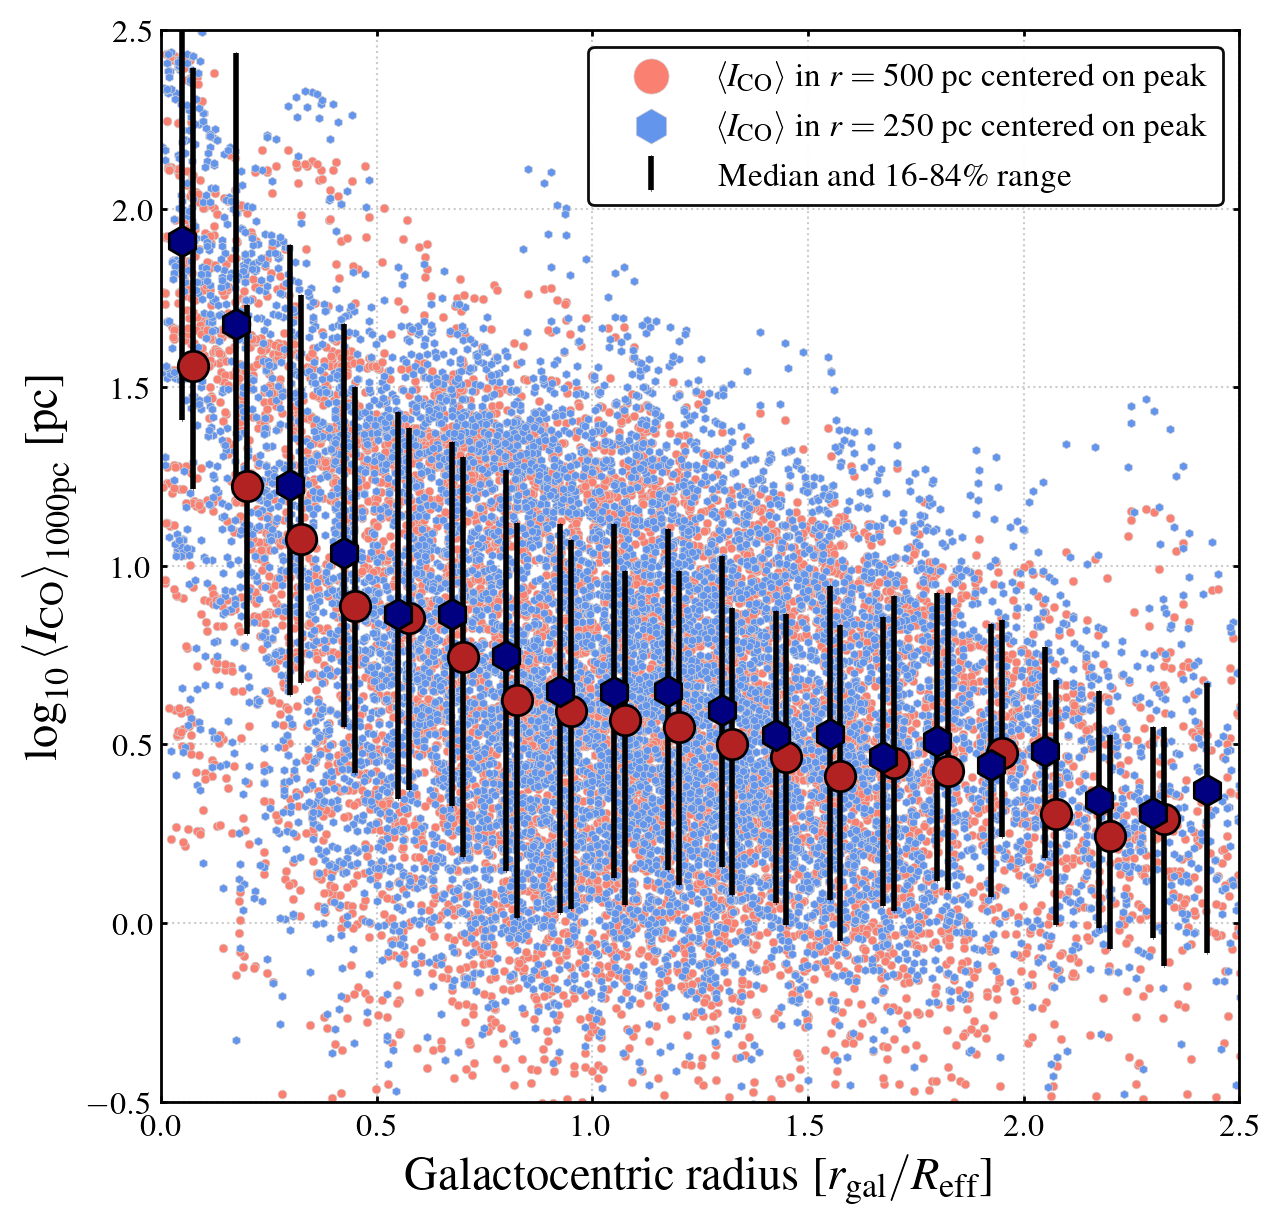

In [91]:
png_name = '../plots/ico_vs_rgal.png'

xmin = 0.0
xmax = 2.5
ymin = -0.5
ymax = 2.5

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})


xlabel = r'Galactocentric radius [$r_{\rm gal}/R_{\rm eff}$]'
ylabel = r'$\log_{10} \left< I_{\rm CO} \right>_{\rm 1000 pc}$ [pc]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    deets = deets_dict[this_source]
    this_size = np.array(deets['size_reff'])        
    this_x = np.array(this_tab['RGAL_DEG'])*3600./this_size
    this_y = np.array(this_tab['ICO21_1KPC'])    
    this_z = np.array(this_tab['ICO21_500PC'])    
    x_list.append(this_x)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.0625,2.5,0.125)

ybins = bin_data((x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data((x_vec), z_vec, xlo=xlo, xhi=xhi)

axes.scatter((x_vec), np.log10(y_vec), marker='o', s=10
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$\left<I_{\rm CO}\right>$ in $r=500$~pc centered on peak')

axes.scatter((x_vec), np.log10(z_vec), marker='h', s=10
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$\left<I_{\rm CO}\right>$ in $r=250$~pc centered on peak')

shift = 0.05
axes.scatter(ybins['xmid']-shift, np.log10(ybins['50']), marker='o', s=120
             , facecolor='firebrick', edgecolor='black'
             , zorder=5)
axes.errorbar(ybins['xmid']-shift, np.log10(ybins['50']),
                [np.log10(ybins['84'])-np.log10(ybins['50']),
                 np.log10(ybins['50'])-np.log10(ybins['16'])],
              color='black', capsize=0.1, elinewidth=2, fmt='none',
              marker='o',s=10,
              zorder=3,label=r'Median and 16-84\% range')

axes.scatter(zbins['xmid']+shift, np.log10(zbins['50']), marker='h', s=120
             , facecolor='navy', edgecolor='black'
             , zorder=6)
axes.errorbar(zbins['xmid']+shift, np.log10(zbins['50']),
                [np.log10(zbins['84'])-np.log10(zbins['50']),
                 np.log10(zbins['50'])-np.log10(zbins['16'])],
              color='black', capsize=0.1, elinewidth=2, fmt='none',
              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.95, loc='upper right', 
            ncol=1, fontsize=12, handlelength=3, markerscale=4)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

/tmp/ipykernel_3778782/3035922662.py:61: RuntimeWarning: divide by zero encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/3035922662.py:62: RuntimeWarning: divide by zero encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/tmp/ipykernel_3778782/3035922662.py:65: RuntimeWarning: divide by zero encountered in log10
  axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=10
/tmp/ipykernel_3778782/3035922662.py:70: RuntimeWarning: divide by zero encountered in log10
  axes.scatter(np.log10(x_vec), (z_vec+z_noise), marker='h', s=10


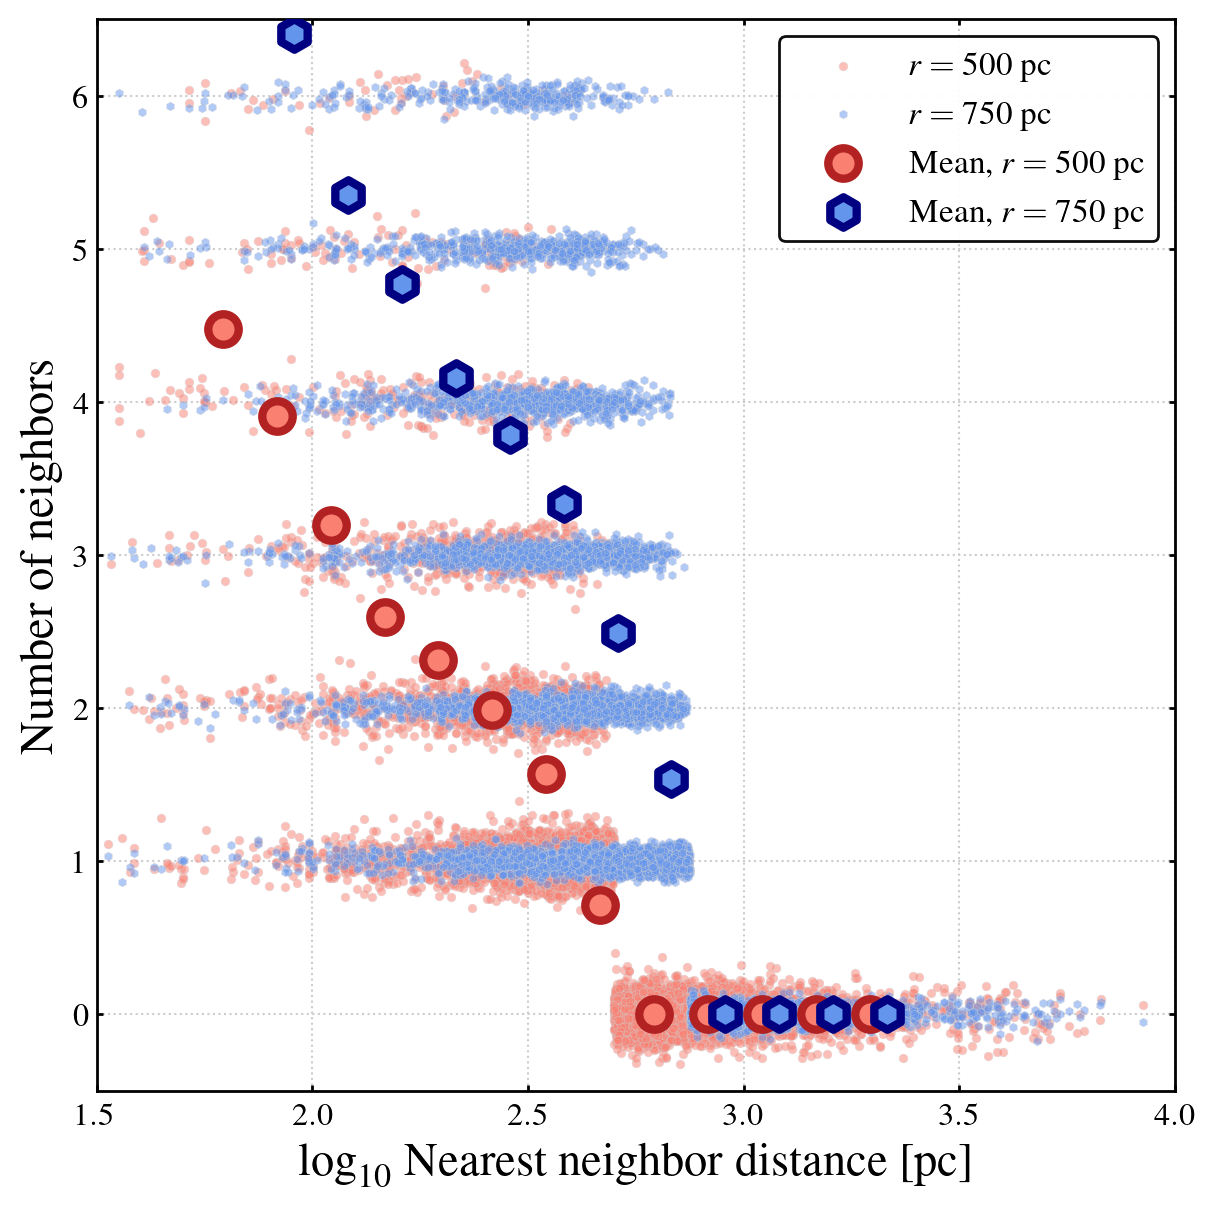

In [92]:
png_name = '../plots/nn_vs_dist.png'

xmin = 1.5
xmax = 4.
ymin = -0.5
ymax = 6.5

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ Nearest neighbor distance [pc]'
ylabel = r'Number of neighbors'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    #print(this_source)
    this_x = np.array(this_tab['DIST_NN1_PC'])  
    this_y = np.array(this_tab['NEIGHBORS_500PC'])
    this_z = np.array(this_tab['NEIGHBORS_750PC'])
    x_list.append(this_x)    
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(1.75,3.5,0.125)

ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)

y_noise = y_vec*0. + np.random.normal(size=len(y_vec))*0.10
axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=10
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$r=500$~pc',alpha=0.5)

z_noise = z_vec*0. + np.random.normal(size=len(z_vec))*0.05
axes.scatter(np.log10(x_vec), (z_vec+z_noise), marker='h', s=10
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$r=750$~pc',alpha=0.5)

shift = 0.02
axes.scatter(ybins['xmid']-shift, (ybins['mean']), marker='o', s=120
             , facecolor='salmon', edgecolor='firebrick', linewidth=3
             , zorder=6, label=r'Mean, $r=500$~pc')
#axes.errorbar(ybins['xmid']-shift, (ybins['mean']), (ybins['stddev'])
#              , color='black', capsize=0.1, elinewidth=2, fmt='none'
#              , marker='o',s=10
#              , zorder=3,label=r'Median and std. dev.')

axes.scatter(zbins['xmid']+shift, (zbins['mean']), marker='h', s=120
             , facecolor='cornflowerblue', edgecolor='navy', linewidth=3
             , zorder=6, label=r'Mean, $r=750$~pc')
#axes.errorbar(zbins['xmid']+shift,(zbins['mean']),
#                [(zbins['84'])-(zbins['50']),
#                 (zbins['50'])-(zbins['16'])],
#              color='black', capsize=0.1, elinewidth=2, fmt='none',
#              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.95, loc='upper right', 
            ncol=1, fontsize=12, handlelength=3, markerscale=1)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')